For number of photons,

$N= \sum_{k,s} n_k =2\sum_{k} n_k=\frac{2V}{(2π)^3}4π∫_{0}^{∞}dk⋅k^2\frac{1}{e^{βħck}\space -1}$

Hence for number density n,

$n=\frac{N}{V}=\frac{1}{π^2}∫_0^∞\frac{v^2}{e^{\frac{hv}{k_BT}}-1} dv=\frac{1}{π^2}∫_0^∞ dx\cdot \frac{x^2}{e^x-1} (\frac{k_BT}{ħc})^3= \frac{1}{π^2}2ζ(3) (\frac{k_BT}{ħc})^3$ (where v is the frequency of the photon and the integral is calculated using the program below)

And since energy density= $\frac{\pi^2}{15}\frac{(k_BT)^4}{(\hbar c)^3}$

Average energy of a photon = $\frac{energy\ density}{number\ density}=\frac{\pi^4}{30ζ(3)}k_BT=2.701k_BT$

The computation result is shown below.

In [18]:
import numpy as np
import scipy as sp
from scipy import constants
import scipy.integrate as integrate
from scipy.integrate import quad
Energy_density=(constants.pi**2)/15*(constants.Boltzmann)**4/(constants.hbar*constants.c)**3
print('Energy density=', Energy_density,'T^4')
def integrand(x):
    return x**2 / np.expm1(x)
I = quad(integrand, 0, np.inf)
print('Integral=', I[0])
Number_density=(I[0]/constants.pi**2)*(constants.Boltzmann)**3/(constants.hbar*constants.c)**3
print('Number density=', Number_density, 'T^3')
print('Average energy of a photon <E_bb>=', Energy_density/Number_density,'T','or=', Energy_density/Number_density/constants.Boltzmann, 'kT')


Energy density= 7.565733250280003e-16 T^4
Integral= 2.404113806319189
Number density= 20286846.03390705 T^3
Average energy of a photon <E_bb>= 3.7293787499716717e-23 T or= 2.701178032919063 kT


/tmp/ipykernel_1200/3035375152.py:9: RuntimeWarning: overflow encountered in expm1
  return x**2 / np.expm1(x)




For those photons with energy $\geq E_{gap}$, they will be absorbed and hence account into $n_{absorbed}$  

For $n_{absorbed}$,
$n_{absorbed}=\frac{number\ of\ photons\ with\ Energy \geq E_{gap}}{number\ of\ photons}=\frac{number\ desnity\ of\ photons\ with\ Energy \geq E_{gap}}{number\ density}$

Hence,
$n_{absorbed}=\frac{\frac{1}{π^2}∫_{v_{gap}}^∞\frac{v^2}{e^{\frac{hv}{k_BT}}-1} dv}{\frac{1}{π^2}∫_0^∞\frac{v^2}{e^{\frac{hv}{k_BT}}-1} dv}$, where v is the frequency of the photon.

While E=hv, so $v=\frac{E}{h}$ and $dv=\frac{dE}{h}$, $n_{absorbed}$ becomes

$n_{absorbed}=\frac{\frac{1}{π^2h^3}∫_{E_{gap}}^∞\frac{E^2}{e^{\frac{E}{k_BT}}-1} dE}{\frac{1}{π^2h^3}∫_0^∞\frac{E^2}{e^{\frac{E}{k_BT}}-1} dE}$=$\frac{∫_{E_{gap}}^∞\frac{E^2}{e^{\frac{E}{k_BT}}-1} dE}{∫_0^∞\frac{E^2}{e^{\frac{E}{k_BT}}-1} dE}$

For the denominator, let $x=E/k_BT$,

The denominator becomes: $(k_BT)^3∫_0^∞ dx\cdot \frac{x^2}{e^x-1}=2ζ(3)(k_BT)^3$ (using the result of integral in part a)

Thus,

$n_{absorbed}=\frac{∫_{E_{gap}}^∞\frac{E^2}{e^{\frac{E}{k_BT}}-1} dE}{2ζ(3)(k_BT)^3}$,where the numerator is the integral that cannot be solved analytically




---

Thus

efficiency=$\frac{∫_{E_{gap}}^∞\frac{E^2}{e^{\frac{E}{k_BT}}-1} dE}{2ζ(3)(k_BT)^3}\cdot \frac{E_{gap}}{2.701k_BT}=\frac{(k_BT)^3∫_{x}^∞\frac{x^2}{e^{x}-1} dx}{2ζ(3)(k_BT)^3}\cdot \frac{E_{gap}}{2.701k_BT}=\frac{∫_{x}^∞\frac{x^2}{e^{x}-1} dx}{2.701\cdot 2ζ(3)k_BT}\cdot E_{gap}$

,where x= $\frac{E}{k_BT}$

We will solve the numerator numerically.


/tmp/ipykernel_1200/2443592352.py:15: RuntimeWarning: overflow encountered in expm1
  return x**2 / np.expm1(x)


Peak Efficiency: 43.88%
Optimal Band Gap: 1.064 eV


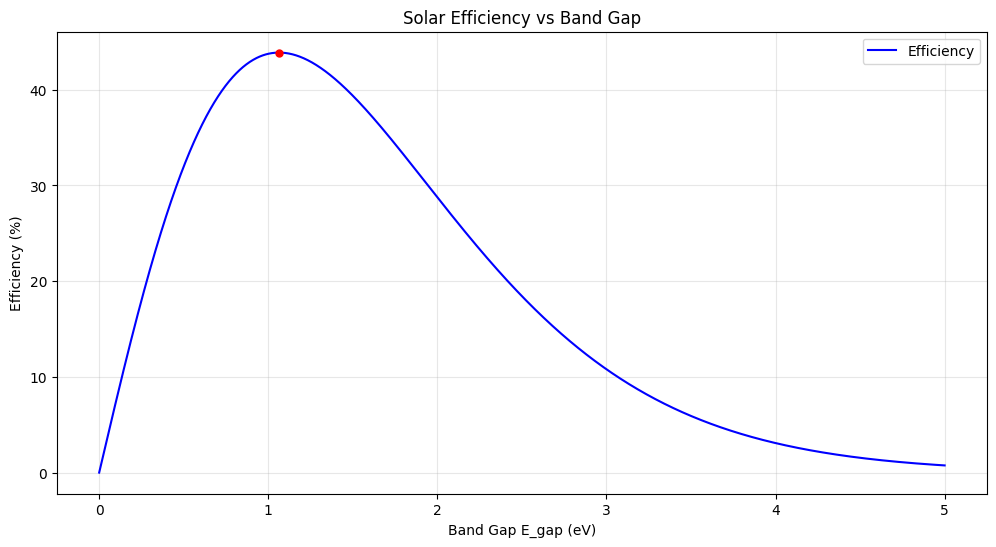

In [19]:
import numpy as np
import pandas as pd
import scipy.special as sp
from scipy import constants
from scipy.integrate import quad
import matplotlib.pyplot as plt

# Constants
T_sun = 5700
k_B_eV = constants.k / constants.e
kT_sun = k_B_eV * T_sun
denominator = kT_sun*(2 * sp.zeta(3))*(constants.pi**4/(30*sp.zeta(3)))

def integrand(x):
    return x**2 / np.expm1(x)

E_gap_vals = np.linspace(0.00001, 5.0, 3000)
eta_vals = []

for Eg in E_gap_vals:
    x_gap = Eg / kT_sun
    numerator, _= quad(integrand, x_gap, np.inf)
    efficiency= numerator*Eg/denominator

    eta_vals.append(efficiency)

eta_vals = np.array(eta_vals)

max_idx = np.argmax(eta_vals)
max_Eg = E_gap_vals[max_idx]
max_eta = eta_vals[max_idx]

print(f"Peak Efficiency: {max_eta*100:.2f}%")
print(f"Optimal Band Gap: {max_Eg:.3f} eV")

plt.figure(figsize=(12, 6))
plt.plot(E_gap_vals, eta_vals * 100, label='Efficiency', color='blue')
plt.plot(max_Eg, max_eta * 100, 'ro', markersize=5) # Red dot at peak

plt.xlabel('Band Gap E_gap (eV)')
plt.ylabel('Efficiency (%)')
plt.title('Solar Efficiency vs Band Gap')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()



---


Optimal band gap of second material = 1.917 eV

Take comparsion between the highest effieciency attained at their optimal bandgap (Si : 1.12eV ; Multi-junction : 1.917eV),

 Efficiency improved = 56.51%-43.88% = 12.64%

 Code is attached below

/tmp/ipykernel_1200/3803825163.py:12: RuntimeWarning: overflow encountered in expm1
  return x**2 / np.expm1(x)


Single-junction Silicon cell efficiency (Eg=1.064 eV): 43.88%

Multi-junction cell results:
Peak Multi-junction Efficiency: 56.51%
Optimal Band Gap for second material (Eg1): 1.917 eV
Improvement over single-junction Si: 12.64%


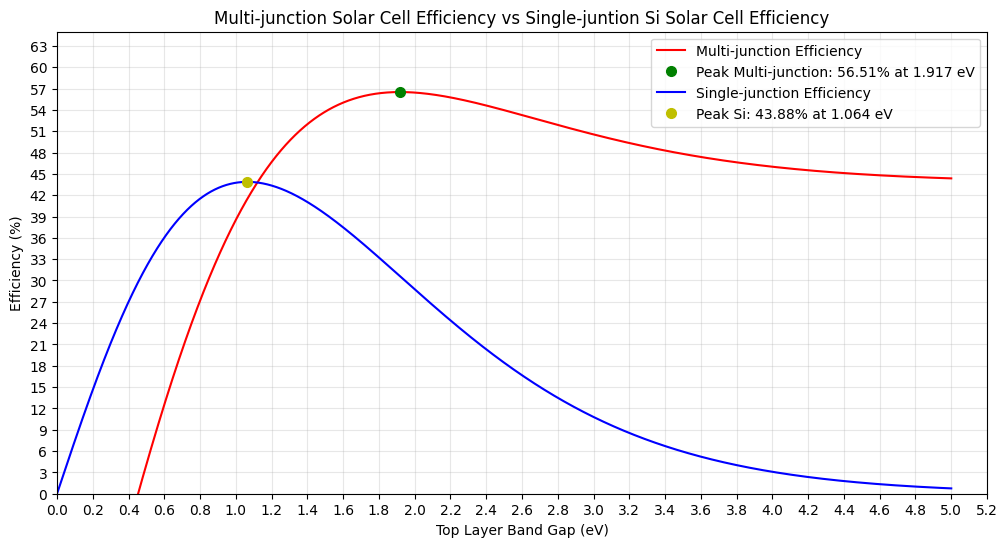

In [20]:
import numpy as np
import scipy.special as sp
from scipy import constants
from scipy.integrate import quad
import matplotlib.pyplot as plt

T_sun = 5700
k_B_eV = constants.k / constants.e
kT_sun = k_B_eV * T_sun
denominator = kT_sun*(2 * sp.zeta(3))*(constants.pi**4/(30*sp.zeta(3)))
def integrand(x):
    return x**2 / np.expm1(x)

Eg_Si=1.12
E_gap_vals = np.linspace(0.00001, 5.0, 3000)
eta_vals = []

for Eg in E_gap_vals:
    x_gap = Eg / kT_sun
    numerator, _= quad(integrand, x_gap, np.inf)
    efficiency= numerator*Eg/denominator

    eta_vals.append(efficiency)

eta_vals = np.array(eta_vals)

max_idx = np.argmax(eta_vals)
max_Eg = E_gap_vals[max_idx]
max_eta = eta_vals[max_idx]

print(f"Single-junction Silicon cell efficiency (Eg={max_Eg:.3f} eV): {max_eta*100:.2f}%")

Eg1_vals = np.linspace(0.00001, 5.0, 3000)
eta_multi_junction_vals = []

for Eg1 in Eg1_vals:

    x1 = Eg1 / kT_sun
    numerator_top, _ = quad(integrand, x1, np.inf)
    eta_top = numerator_top * Eg1 / denominator


    x_Si_bottom = Eg_Si / kT_sun
    numerator_bottom, _ = quad(integrand, x_Si_bottom, x1)
    eta_bottom = numerator_bottom * Eg_Si / denominator

    eta_multi_junction = eta_top + eta_bottom
    eta_multi_junction_vals.append(eta_multi_junction)

eta_multi_junction_vals = np.array(eta_multi_junction_vals)

max_idx_multi = np.argmax(eta_multi_junction_vals)
max_Eg1_multi = Eg1_vals[max_idx_multi]
max_eta_multi = eta_multi_junction_vals[max_idx_multi]

print(f"\nMulti-junction cell results:")
print(f"Peak Multi-junction Efficiency: {max_eta_multi*100:.2f}%")
print(f"Optimal Band Gap for second material (Eg1): {max_Eg1_multi:.3f} eV")
print(f"Improvement over single-junction Si: {(max_eta_multi - max_eta)*100:.2f}%")

plt.figure(figsize=(12, 6))
plt.xticks([i/5 for i in range(50)])
plt.yticks([3*i for i in range(25)])
plt.xlim(left=0, right=5.2)
plt.plot(Eg1_vals, eta_multi_junction_vals * 100, label='Multi-junction Efficiency' , color='red')
plt.plot(max_Eg1_multi, max_eta_multi * 100, 'go', markersize=7, label=f'Peak Multi-junction: {max_eta_multi*100:.2f}% at {max_Eg1_multi:.3f} eV')
plt.plot(E_gap_vals, eta_vals * 100, label='Single-junction Efficiency', color='blue')
plt.plot(max_Eg, max_eta * 100, 'yo', markersize=7, label=f'Peak Si: {max_eta*100:.2f}% at {max_Eg:.3f} eV')
plt.ylim(0,65)
plt.xlabel('Top Layer Band Gap (eV)')
plt.ylabel('Efficiency (%)')
plt.title('Multi-junction Solar Cell Efficiency vs Single-juntion Si Solar Cell Efficiency')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()